> **Corrida real en Databricks (serverless), 22 de octubre de 2026.** Este archivo guarda las salidas tal como quedaron en el workspace: descarga, procesamiento del DENUE (2,774,429 filas), índice de las 92 metrópolis, validación (69 reglas: 66 OK, 3 AVISO, 0 FALLA), las tres gráficas y las 7 tablas Delta registradas en `workspace.mccain_papa`. Para volver a correrlo se usa `04_indice_databricks.ipynb` (ver `docs/databricks.md`).

# Datos Masivos — McCain: ¿dónde invertir para vender más papas a la francesa?

**Índice de inversión por zona metropolitana, en Databricks**

McCain no compra papa mexicana: importa papa congelada (variedades como Russet) y la vende a
restaurantes. La pregunta que sí le sirve es **dónde está creciendo la demanda**:

> Si McCain tuviera X millones para crecer en México, ¿en qué zonas metropolitanas los pondría?

Para cada una de las **92 zonas metropolitanas de CONAPO** calculamos cuatro componentes con el
DENUE de INEGI (2019 contra 2026), los convertimos en percentiles de 0 a 100 y los promediamos
con el **mismo peso** (25% cada uno):

| Componente | Qué mide | Fuente |
|---|---|---|
| A. Crecimiento | tasa anual de restaurantes donde se venden papas (comida rápida y a la carta) | DENUE |
| B. Cadenas | aperturas netas de McDonald's, KFC, Carl's Jr., Burger King… por 100 mil habitantes | DENUE |
| Turismo | hoteles por 100 mil habitantes | DENUE |
| Mercado | número de restaurantes objetivo hoy | DENUE |
| C. Competencia | de qué país vienen las papas importadas y a qué precio por kilo (nacional) | UN Comtrade |

Igual que el notebook 03, aquí no copiamos código: llamamos a los módulos de `src/` del
repositorio. **Cómo correrlo:** conectar a *Serverless* y dar **Run all** (unos 15 minutos la
primera vez, por la descarga del DENUE).

## 0. Instalar librerías

In [0]:
%pip install -q beautifulsoup4 pyyaml

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
dbutils.library.restartPython()

## 1. Configurar el data lake

Mismo Volume que el notebook 03. Las fuentes nuevas quedan en sus propias carpetas:
`raw/denue/<versión>/`, `raw/metropolis/` y `raw/comtrade/`.

In [0]:
import os
import sys
from pathlib import Path

CATALOGO = "workspace"
ESQUEMA = "mccain_papa"
VOLUMEN = "datalake"
LAGO = f"/Volumes/{CATALOGO}/{ESQUEMA}/{VOLUMEN}"

spark.sql(f"CREATE SCHEMA IF NOT EXISTS {CATALOGO}.{ESQUEMA}")
spark.sql(f"CREATE VOLUME IF NOT EXISTS {CATALOGO}.{ESQUEMA}.{VOLUMEN}")

os.environ["DATOS_MASIVOS_DATA"] = LAGO
os.environ["DATOS_MASIVOS_REPORTS"] = f"{LAGO}/reports"


def encontrar_raiz():
    """Buscamos hacia arriba la carpeta del repo (la que contiene src/)."""
    for candidata in [Path.cwd(), *Path.cwd().parents]:
        if (candidata / "src" / "processing" / "build_dataset.py").exists():
            return candidata
    raise RuntimeError("Abre este notebook desde el Git folder del repositorio.")


RAIZ = encontrar_raiz()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
os.chdir(RAIZ)

from src.utils import rutas
from src.utils.config import cargar_config

CONFIG = cargar_config()
print("Data lake :", rutas.DATA)
print("Versiones del DENUE:", [v["etiqueta"] for v in CONFIG["denue"]["versiones"]])

Data lake : /Volumes/workspace/mccain_papa/datalake
Versiones del DENUE: ['2015_02', '2019_11', '2022_11', '2026_05']


## 2. Adquisición

Tres fuentes, todas abiertas y sin llave:

| Fuente | Qué bajamos | Tamaño |
|---|---|---|
| DENUE (INEGI) | sector 72, 4 versiones: 2015, 2019, 2022 y 2026 (7 zip) | ~300 MB en zip, ~1.5 GB en CSV |
| CONAPO | catálogo de 92 metrópolis y sus municipios | < 1 MB |
| UN Comtrade | importaciones mensuales de papa congelada (HS 200410), 2015–2025 | 132 consultas |

Si Databricks no alcanza INEGI, el plan B es el mismo que en el notebook 03: en local corremos
`python -m src.ingestion.download_data --fuente indice`, comprimimos `data/raw` como
`raw_indice.zip` y lo subimos al Volume.

In [0]:
import requests

PORTALES = {
    "INEGI": "https://www.inegi.org.mx/app/descarga/",
    "Comtrade": "https://comtradeapi.un.org/public/v1/preview/C/M/HS?reporterCode=484&period=202401&cmdCode=200410&flowCode=M",
}


def responde(url):
    try:
        return requests.get(url, timeout=20).status_code < 500
    except requests.RequestException:
        return False


alcance = {fuente: responde(url) for fuente, url in PORTALES.items()}
ZIP = Path(LAGO) / "raw_indice.zip"
MODO = "completo" if all(alcance.values()) else ("zip" if ZIP.exists() else "sin_red")
print("Portales:", alcance, "-> modo", MODO)

Portales: {'INEGI': True, 'Comtrade': True} -> modo completo


In [0]:
import zipfile

from src.ingestion import download_data

if MODO == "completo":
    # Lo que ya bajó se toma de la caché: correr esta celda otra vez no repite descargas.
    codigo = download_data.main(["--fuente", "indice"])
elif MODO == "zip":
    with zipfile.ZipFile(ZIP) as archivo:
        archivo.extractall(LAGO)
    codigo = 0
else:
    raise RuntimeError("Databricks no alcanza INEGI/Comtrade y no hay raw_indice.zip en el Volume")
print("Código de salida:", codigo)

for carpeta in ["denue", "metropolis", "comtrade"]:
    archivos = [a for a in (rutas.RAW / carpeta).rglob("*") if a.is_file()]
    mb = sum(a.stat().st_size for a in archivos) / 1024**2
    print(f"raw/{carpeta:10s} | {len(archivos):4d} archivos | {mb:7.1f} MB")

2026-10-22 21:27:51 | INFO    | ingestion | CONAPO municipios | en cache
2026-10-22 21:27:51 | INFO    | ingestion | CONAPO caracteristicas | en cache
2026-10-22 21:27:58 | INFO    | ingestion | DENUE 2015_02 | denue_72_25022015_csv.zip en cache
2026-10-22 21:27:58 | INFO    | ingestion | DENUE 2019_11 | denue_00_72_1_1119_csv.zip en cache
2026-10-22 21:27:58 | INFO    | ingestion | DENUE 2019_11 | denue_00_72_2_1119_csv.zip en cache
2026-10-22 21:27:58 | INFO    | ingestion | DENUE 2022_11 | denue_00_72_1_1122_csv.zip en cache
2026-10-22 21:27:58 | INFO    | ingestion | DENUE 2022_11 | denue_00_72_2_1122_csv.zip en cache
2026-10-22 21:27:58 | INFO    | ingestion | DENUE 2026_05 | denue_00_72_1_csv.zip en cache
2026-10-22 21:27:58 | INFO    | ingestion | DENUE 2026_05 | denue_00_72_2_csv.zip en cache
2026-10-22 21:27:58 | INFO    | ingestion | Adquisicion terminada en 7.5 s | errores: 0


Código de salida: 0
raw/denue      |    7 archivos |   225.0 MB
raw/metropolis |    4 archivos |     0.1 MB
raw/comtrade   |  132 archivos |     0.6 MB


## 3. Procesamiento con Spark

`build_dataset --fuente indice` extrae los CSV de los zip, lee cada versión del DENUE con su
propia codificación (2015 viene en UTF-8 con encabezados largos; 2019 en adelante en Latin-1 con
encabezados cortos), las une con `unionByName` y escribe `interim/` y `processed/` particionados
por versión.

In [0]:
import json

from src.processing import build_dataset

codigo = build_dataset.main(["--fuente", "indice"])
print("Código de salida:", codigo)
resumen = json.loads((rutas.PROCESSED / "resumen_build.json").read_text())
resumen["indice"]

2026-10-22 21:28:07 | INFO    | processing | CONAPO | 92 metropolis, 421 municipios
2026-10-22 21:28:10 | INFO    | processing | Comtrade | 527 filas mes-pais
2026-10-22 21:28:48 | INFO    | processing | DENUE | interim 2,774,445 -> processed 2,774,429 | sin llave 0 | duplicados 16 | 37.77 s
2026-10-22 21:28:48 | INFO    | processing | Dataset construido en 48.15 s -> /Volumes/workspace/mccain_papa/datalake/processed


Código de salida: 0


{'metropolis': {'municipios': 421, 'metropolis': 92},
 'comtrade_filas': 527,
 'denue': {'filas_interim': 2774445,
  'filas_sin_llave': 0,
  'filas_duplicadas': 16,
  'filas_processed': 2774429,
  'segundos': 37.77}}

In [0]:
from pyspark.sql import functions as F

denue = spark.read.parquet(str(rutas.PROCESSED / "denue_establecimientos"))
display(
    denue.groupBy("version")
    .pivot("categoria")
    .count()
    .orderBy("version")
)

version,a_la_carta,autoservicio,bares,comida_rapida,hoteles,otros
2015_02,58195,4502,26510,55029,16589,408041
2019_11,60267,20670,29342,61176,17295,509062
2022_11,64985,10296,28639,67955,17908,511473
2026_05,72520,16605,30451,79622,19340,587957


## 4. Índice de inversión

Cruzamos el DENUE con el catálogo de municipios de CONAPO (*broadcast join*: el catálogo tiene
~420 filas), contamos por metrópoli y versión, y calculamos los percentiles con una *window*.

In [0]:
from src.analysis import indice_inversion

codigo = indice_inversion.main()
print("Código de salida:", codigo)

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(
2026-10-22 21:29:08 | INFO    | analysis |  1. Los Cabos                    indice  82.7 | crecimiento   5.4%/anio | turismo y aperturas de cadenas
2026-10-22 21:29:08 | INFO    | analysis |  2. Acapulco                     indice  73.4 | crecimiento   2.8%/anio | turismo y aperturas de cadenas
2026-10-22 21:29:08 | INFO    | analysis |  3. Guanajuato                   indice  73.1 | crecimiento   4.3%/anio | aperturas de cadenas y turismo
2026-10-22 21:29:08 | INFO    | analysis |  4. Tecomán                      indice  72.0 | crecimiento   6.9%/anio | crecimiento de restaurantes y turismo
2026-10-22 21:29:08 | INFO    | analysis |  5. Tapachula                    indice  71.1 | crecimiento   3.7%/anio | turismo y ap

Código de salida: 0


## 5. Validación

In [0]:
import pandas as pd

from src.validation import validate_dataset

codigo = validate_dataset.main()
validacion = pd.read_csv(rutas.TABLAS / "validacion.csv")
print("Código de salida:", codigo, validacion.estado.value_counts().to_dict())
display(validacion[validacion.tabla.isin(["denue", "metropolis", "metropolis_municipios",
                                          "importaciones", "indice"])])

2026-10-22 21:29:41 | INFO    | validation | OK    | siap         | columnas requeridas                      | 13 columnas presentes
2026-10-22 21:29:41 | INFO    | validation | OK    | sniim        | columnas requeridas                      | 12 columnas presentes
2026-10-22 21:29:41 | INFO    | validation | OK    | canalizacion | columnas requeridas                      | 6 columnas presentes
2026-10-22 21:29:41 | INFO    | validation | OK    | siap         | tipos de datos                           | 13 columnas con el tipo esperado
2026-10-22 21:29:41 | INFO    | validation | OK    | sniim        | tipos de datos                           | 12 columnas con el tipo esperado
2026-10-22 21:29:41 | INFO    | validation | OK    | canalizacion | tipos de datos                           | 6 columnas con el tipo esperado
2026-10-22 21:29:41 | INFO    | validation | OK    | siap         | nulos en estado                          | 0 de 3,171 (max 0%)
2026-10-22 21:29:41 | INFO    | validati

Código de salida: 0 {'OK': 66, 'AVISO': 3}


tabla,regla,estado,valor,detalle
denue,columnas requeridas,OK,10.0,10 columnas presentes
denue,tipos de datos,OK,10.0,10 columnas con el tipo esperado
denue,nulos en nombre_act,OK,0.0,"0 de 2,774,429 (max 1%)"
denue,nulos en fecha_corte,OK,0.0,"0 de 2,774,429 (max 0%)"
denue,nulos en latitud,OK,0.0,"0 de 2,774,429 (max 5%)"
denue,nulos en personal_min,OK,0.0,"0 de 2,774,429 (max 5%)"
denue,duplicados en la llave,OK,0.0,"llave ['version', 'id']"
denue,formato de cve_mun5,OK,0.0,filas que no cumplen ^\d{5}$
denue,rango de latitud,OK,0.0,"valores fuera de [14.0, 33.0]"
denue,rango de longitud,OK,0.0,"valores fuera de [-119.0, -86.0]"


## 6. Gráficas

Las mismas tres gráficas que genera el pipeline en `reports/figures/`, una por pregunta.

In [0]:
from src.analysis import graficas

figuras = graficas.generar_todas(spark)

### ¿Dónde invertir?
Cada barra se parte en lo que aporta cada componente al índice.

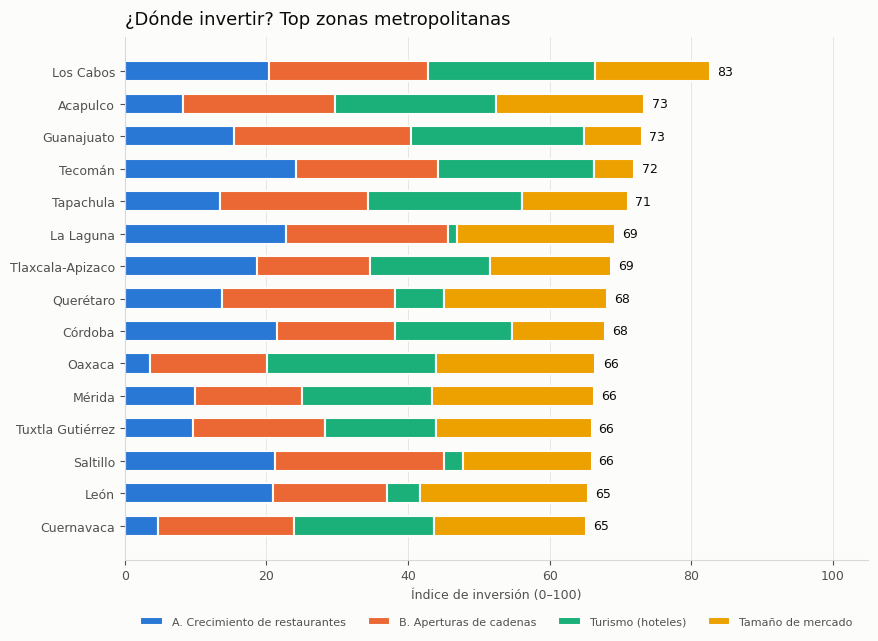

In [0]:
display(figuras["ranking_metropolis"])

### ¿Por qué ahí?
Arriba a la izquierda: crece rápido y todavía hay pocos restaurantes por habitante.

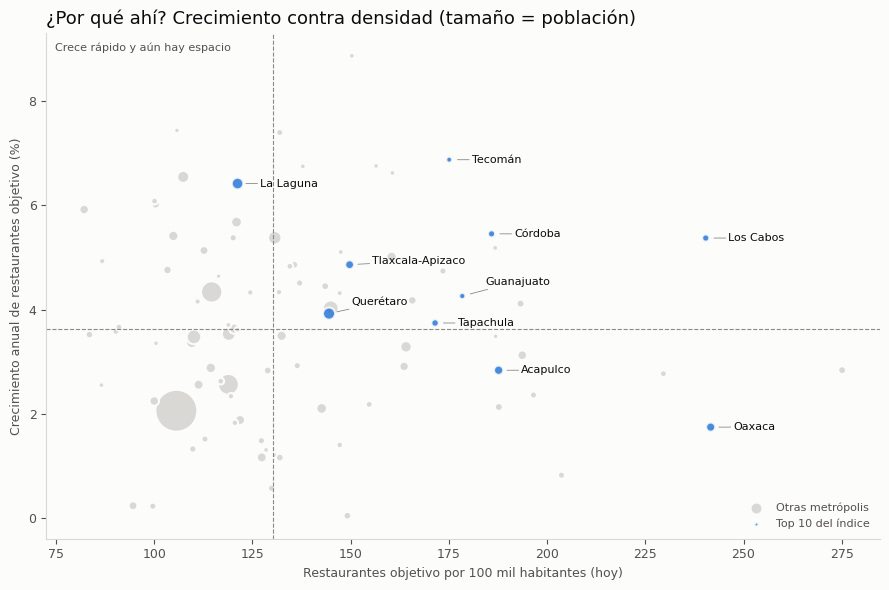

In [0]:
display(figuras["mapa_oportunidad"])

### ¿Contra quién competimos?
De dónde vienen las papas congeladas que importa México y a qué precio por kilo.

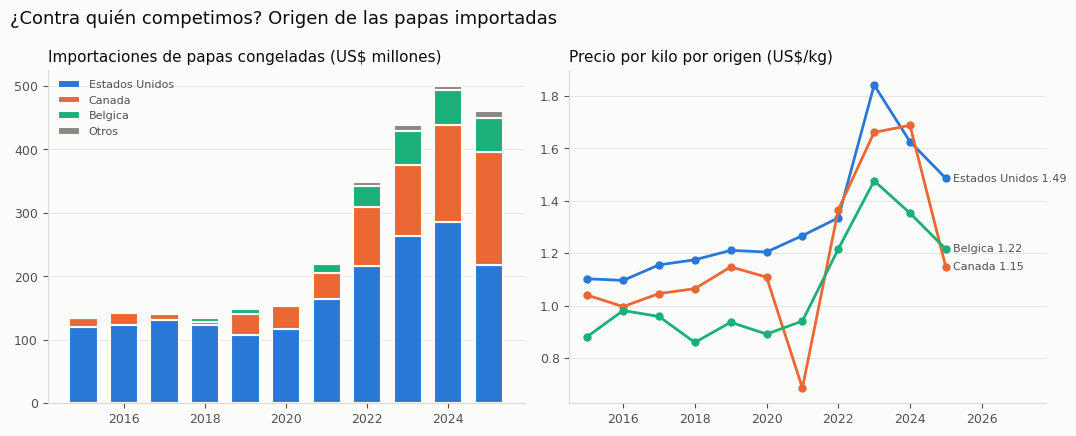

In [0]:
if "competencia_importacion" in figuras:
    display(figuras["competencia_importacion"])

## 7. Tablas en el catálogo

Registramos los resultados como tablas Delta en `workspace.mccain_papa`.

In [0]:
TABLAS_CATALOGO = {
    "indice_inversion": "Indice de inversion por zona metropolitana (0-100) y sus componentes",
    "serie_metropolis": "Restaurantes objetivo, cadenas y hoteles por metropoli y version del DENUE",
    "cadenas_metropolis": "Sucursales por cadena, metropoli y version del DENUE",
    "metropolis": "Catalogo CONAPO 2020: poblacion y PIB por metropoli",
    "importaciones": "Importaciones mensuales de papa congelada por pais (UN Comtrade, HS 200410)",
    "importaciones_anuales": "Importaciones anuales por pais: valor, kilos, US$/kg y participacion",
    "denue_establecimientos": "DENUE sector 72, todas las versiones, con categoria y cadena",
}

for tabla, descripcion in TABLAS_CATALOGO.items():
    ruta = rutas.PROCESSED / tabla
    if not ruta.exists():
        print(f"(sin {tabla})")
        continue
    nombre = f"{CATALOGO}.{ESQUEMA}.{tabla}"
    (spark.read.parquet(str(ruta)).write.mode("overwrite")
     .option("overwriteSchema", "true").saveAsTable(nombre))
    spark.sql(f"COMMENT ON TABLE {nombre} IS '{descripcion}'")
    print(f"{nombre:50s} {spark.table(nombre).count():>10,} filas")

workspace.mccain_papa.indice_inversion                     92 filas
workspace.mccain_papa.serie_metropolis                    368 filas
workspace.mccain_papa.cadenas_metropolis                1,620 filas
workspace.mccain_papa.metropolis                           92 filas
workspace.mccain_papa.importaciones                       527 filas
workspace.mccain_papa.importaciones_anuales                51 filas
workspace.mccain_papa.denue_establecimientos        2,774,429 filas


## 8. Resultado: top 10 de zonas metropolitanas

In [0]:
display(spark.sql(f"""
    SELECT ranking, metropoli,
           indice,
           ROUND(crecimiento_anual, 1)  AS crecimiento_pct_anual,
           ROUND(cadenas_netas_100k, 1) AS cadenas_netas_100k,
           ROUND(hoteles_100k, 1)       AS hoteles_100k,
           objetivo_final               AS restaurantes_objetivo,
           poblacion_2020
    FROM {CATALOGO}.{ESQUEMA}.indice_inversion
    ORDER BY ranking
    LIMIT 10
"""))

ranking,metropoli,indice,crecimiento_pct_anual,cadenas_netas_100k,hoteles_100k,restaurantes_objetivo,poblacion_2020
1,Los Cabos,82.7,5.4,0.9,46.4,844,351111
2,Acapulco,73.4,2.8,0.8,37.1,1463,779566
3,Guanajuato,73.1,4.3,3.6,64.8,347,194500
4,Tecomán,72.0,6.9,0.7,33.3,252,143931
5,Tapachula,71.1,3.7,0.7,33.2,687,400606
6,La Laguna,69.2,6.4,0.9,5.7,1667,1375248
7,Tlaxcala-Apizaco,68.7,4.9,0.1,17.9,1010,674510
8,Querétaro,68.1,3.9,1.5,9.7,2212,1530820
9,Córdoba,67.8,5.5,0.3,17.3,633,340564
10,Oaxaca,66.5,1.7,0.3,48.9,1800,744912


**Para verla como gráfica de Databricks** (además de las de arriba):

1. En la tabla de resultados de la celda anterior, dar clic en **+** → **Visualization**.
2. *Visualization type*: **Bar**.
3. *X column*: `metropoli`. *Y columns*: `indice` (agregación **Sum**).
4. En la pestaña **X axis**, *Sort values*: desactivado, para respetar el orden del ranking.
5. **Save**. La gráfica queda guardada en el notebook, debajo de la tabla.

In [0]:
display(spark.sql(f"""
    SELECT anio, pais, ROUND(valor_usd / 1e6, 1) AS millones_usd,
           ROUND(usd_kg, 2) AS usd_kg, ROUND(participacion, 1) AS participacion_pct
    FROM {CATALOGO}.{ESQUEMA}.importaciones_anuales
    WHERE participacion >= 1
    ORDER BY anio DESC, valor_usd DESC
"""))

anio,pais,millones_usd,usd_kg,participacion_pct
2025,Estados Unidos,218.0,1.49,47.4
2025,Canada,177.5,1.15,38.6
2025,Belgica,53.5,1.22,11.6
2025,Paises Bajos,6.0,1.33,1.3
2024,Estados Unidos,286.0,1.63,57.2
2024,Canada,152.6,1.69,30.5
2024,Belgica,55.2,1.35,11.0
2024,Paises Bajos,5.1,1.46,1.0
2023,Estados Unidos,264.3,1.84,60.3
2023,Canada,111.8,1.66,25.5


## 9. Partition pruning sobre el DENUE

`denue_establecimientos` está particionada por `version`. Al pedir solo 2026, Spark lee una de
las cuatro carpetas: buscamos `PartitionFilters` en el plan.

In [0]:
(spark.read.parquet(str(rutas.PROCESSED / "denue_establecimientos"))
 .filter(F.col("version") == "2026_05")
 .groupBy("cadena").count()
 .explain(mode="formatted"))

== Physical Plan ==
AdaptiveSparkPlan (10)
+- == Initial Plan ==
   PhotonResultStage (9)
   +- PhotonColumnarToRow (8)
      +- PhotonGroupingAgg (7)
         +- PhotonShuffleExchangeSource (6)
            +- PhotonShuffleMapStage (5)
               +- PhotonShuffleExchangeSink (4)
                  +- PhotonGroupingAgg (3)
                     +- PhotonProject (2)
                        +- PhotonScan parquet  (1)


(1) PhotonScan parquet 
Output [2]: [cadena#33272, version#33284]
Location: InMemoryFileIndex [dbfs:/Volumes/workspace/mccain_papa/datalake/processed/denue_establecimientos]
PartitionFilters: [isnotnull(version#33284), (version#33284 = 2026_05)]
ReadSchema: struct<cadena:string>

(2) PhotonProject
Input [2]: [cadena#33272, version#33284]
Arguments: [cadena#33272]

(3) PhotonGroupingAgg
Input [1]: [cadena#33272]
Arguments: [cadena#33272], [partial_count(1) AS count#33290L], [count#33289L], [cadena#33272, count#33290L], false

(4) PhotonShuffleExchangeSink
Input [2]: [caden

## 10. Conclusión

1. **La pregunta cambió a una que McCain puede usar:** dónde crece la demanda de papa a la
   francesa, no dónde se siembra papa.
2. **El índice ordena las 92 metrópolis** con cuatro componentes de peso igual; la tabla
   `indice_inversion` dice cuál pesa más en cada una.
3. **La competencia es nacional:** Comtrade muestra de qué país vienen las papas importadas y a
   qué precio por kilo.
4. **Mismo pipeline local y en Databricks**, con el data lake en el Volume y las tablas en
   Unity Catalog.